# 1 · How COVID-19 hit each asset class
Fifteen series across equities, credit, Treasuries, commodities, FX, crypto and the VIX, split into four regimes:

| Period | Dates |
|---|---|
| Pre-COVID | Jan 2018 – 19 Feb 2020 (S&P 500 peak) |
| Crash | 20 Feb – 30 Apr 2020 |
| Recovery | May 2020 – Dec 2021 |
| Post-COVID | 2022 – 2024 (inflation and rate-hike cycle) |

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
from covidmkt import data as D
px = D.load_prices("../data/prices.csv")          # refresh: python scripts/fetch_data.py
rets = D.log_returns(px)
def shade(ax):
    for p, (s, e) in D.PERIODS.items():
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e), color=D.PERIOD_COLORS[p], alpha=0.07)
print(f"{len(px):,} trading days, {px.shape[1]} series, {px.index[0]:%Y-%m-%d} -> {px.index[-1]:%Y-%m-%d}")
from covidmkt import regimes, correlation

1,761 trading days, 15 series, 2018-01-02 -> 2024-12-31


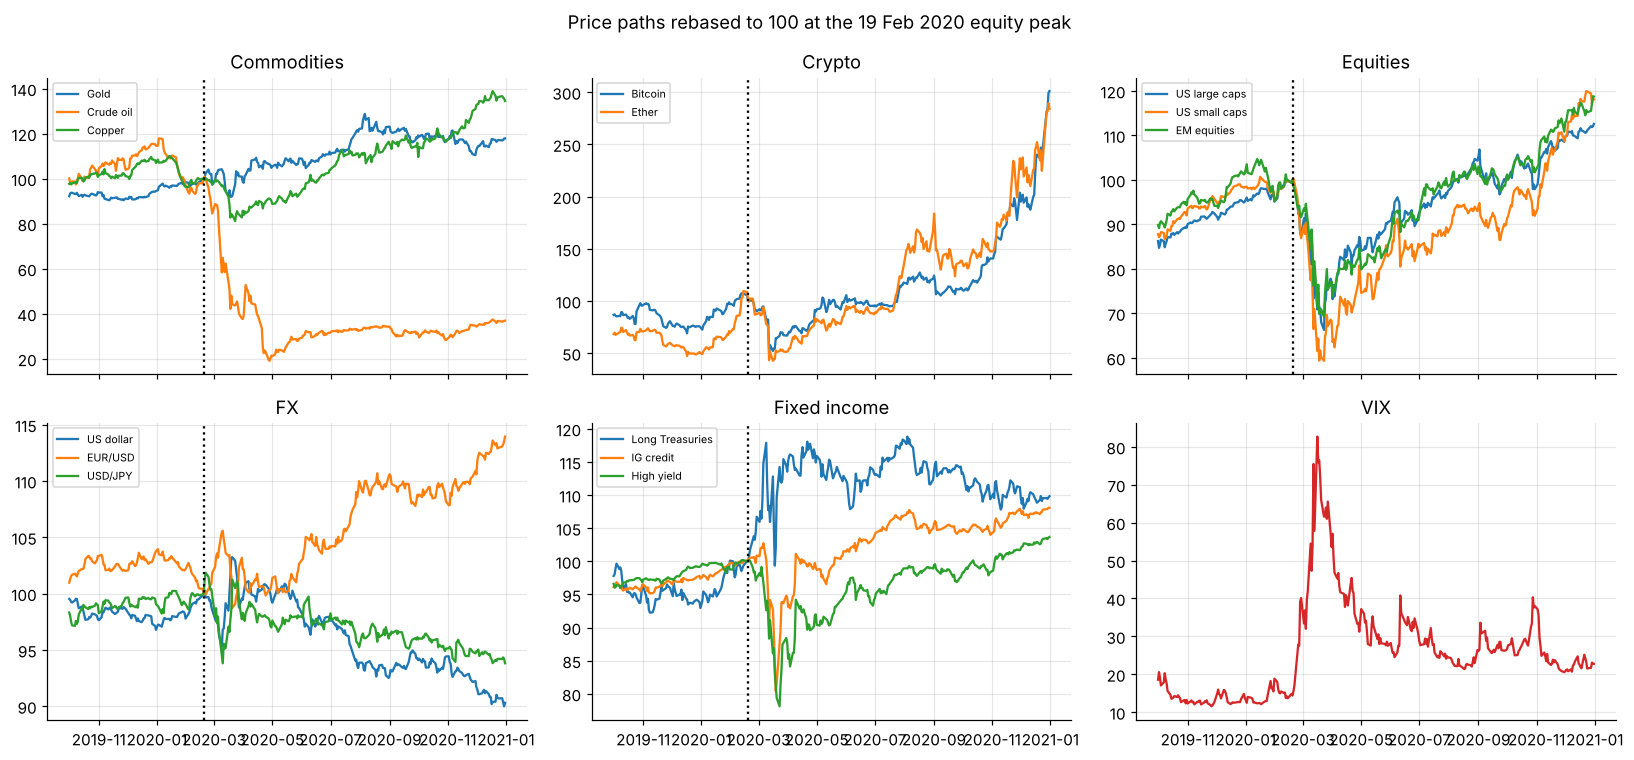

In [2]:
w = px.loc["2019-10-01":"2020-12-31"].drop(columns="^VIX")
norm = w / w.loc[:"2020-02-19"].iloc[-1] * 100
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, (g, members) in zip(axes.flat, D.ASSETS[D.ASSETS.group != "Volatility"].groupby("group")):
    for t in members.index: ax.plot(norm[t], label=D.ASSETS.loc[t, "name"])
    ax.axvline(pd.Timestamp("2020-02-19"), color="k", ls=":"); ax.set_title(g); ax.legend(fontsize=7)
axes.flat[-1].plot(px.loc["2019-10-01":"2020-12-31", "^VIX"], color="tab:red"); axes.flat[-1].set_title("VIX")
fig.suptitle("Price paths rebased to 100 at the 19 Feb 2020 equity peak"); fig.tight_layout()
plt.savefig(IMG / "crash_paths.png", bbox_inches="tight"); plt.show()

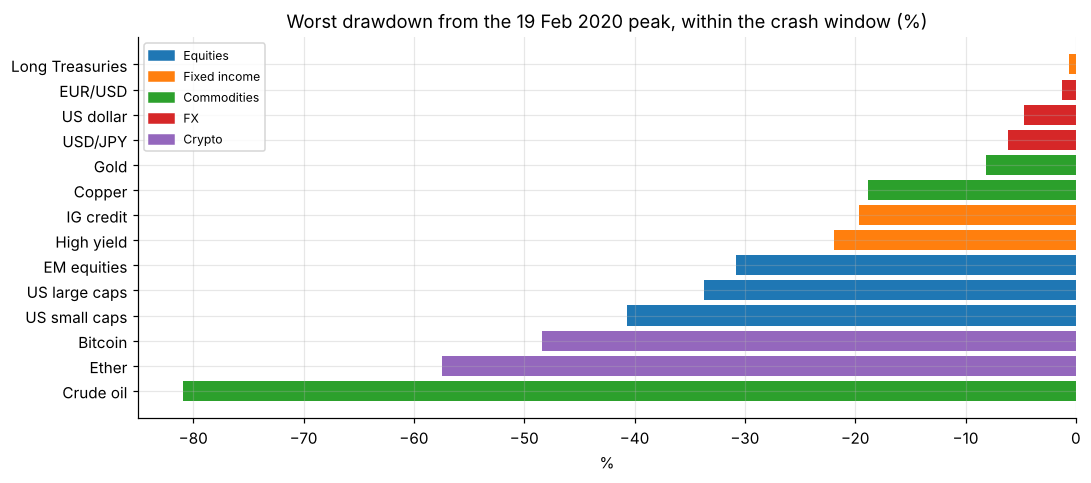

In [3]:
dd = regimes.crash_drawdowns(px.drop(columns="^VIX")).sort_values()
colors = [sns.color_palette()[list(D.ASSETS.group.unique()).index(D.ASSETS.loc[t, "group"])] for t in dd.index]
plt.barh(D.label(dd.index), dd.values * 100, color=colors)
from matplotlib.patches import Patch
groups = list(D.ASSETS.group.unique())
plt.legend(handles=[Patch(color=sns.color_palette()[i], label=g) for i, g in enumerate(groups) if g != "Volatility"], loc="upper left", fontsize=8)
plt.title("Worst drawdown from the 19 Feb 2020 peak, within the crash window (%)"); plt.xlabel("%")
plt.savefig(IMG / "crash_drawdowns.png", bbox_inches="tight"); plt.show()

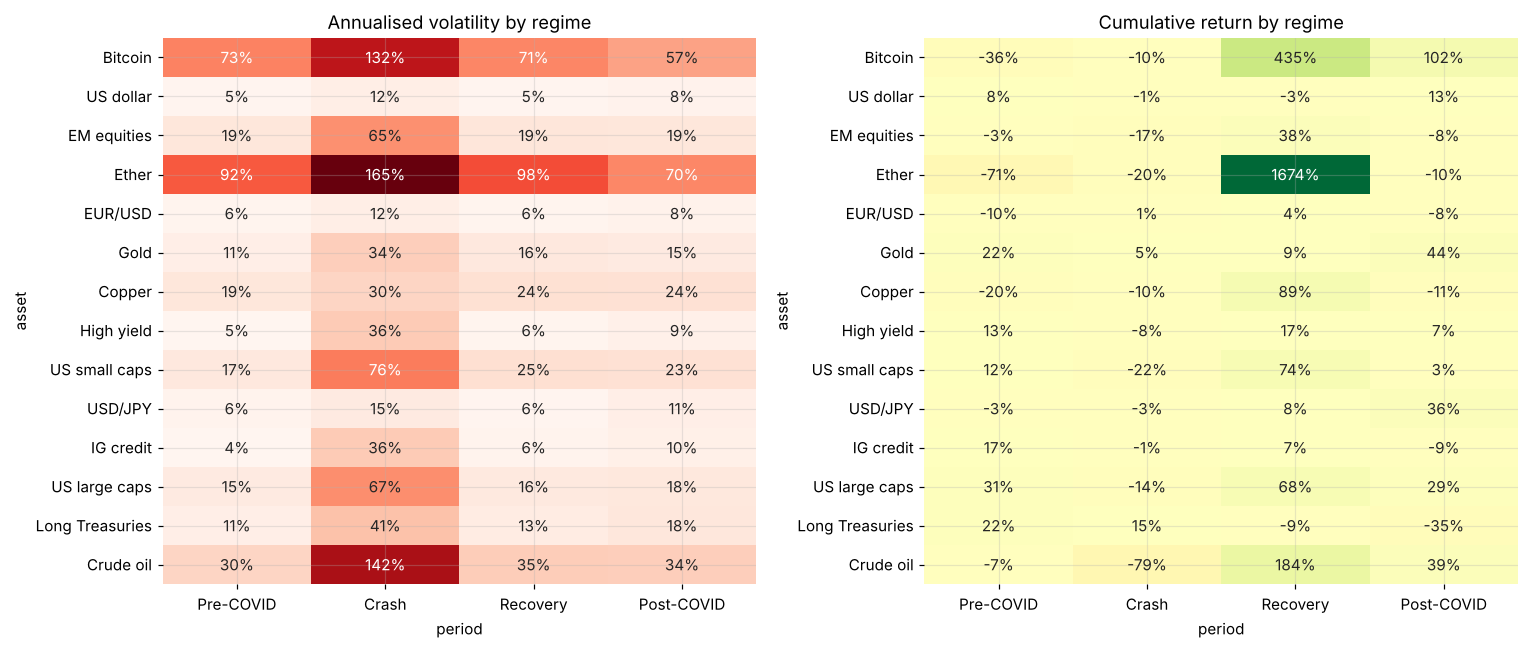

In [4]:
st = regimes.period_stats(rets)
vol = st.pivot(index="asset", columns="period", values="ann. vol")[list(D.PERIODS)]
cum = st.pivot(index="asset", columns="period", values="cum. return")[list(D.PERIODS)]
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(vol.rename(index=dict(zip(vol.index, D.label(vol.index)))), annot=True, fmt=".0%", cmap="Reds", ax=ax[0], cbar=False)
ax[0].set_title("Annualised volatility by regime")
sns.heatmap(cum.rename(index=dict(zip(cum.index, D.label(cum.index)))), annot=True, fmt=".0%", cmap="RdYlGn", center=0, ax=ax[1], cbar=False)
ax[1].set_title("Cumulative return by regime"); fig.tight_layout()
plt.savefig(IMG / "regime_heatmaps.png", bbox_inches="tight"); plt.show()

## Correlation regimes

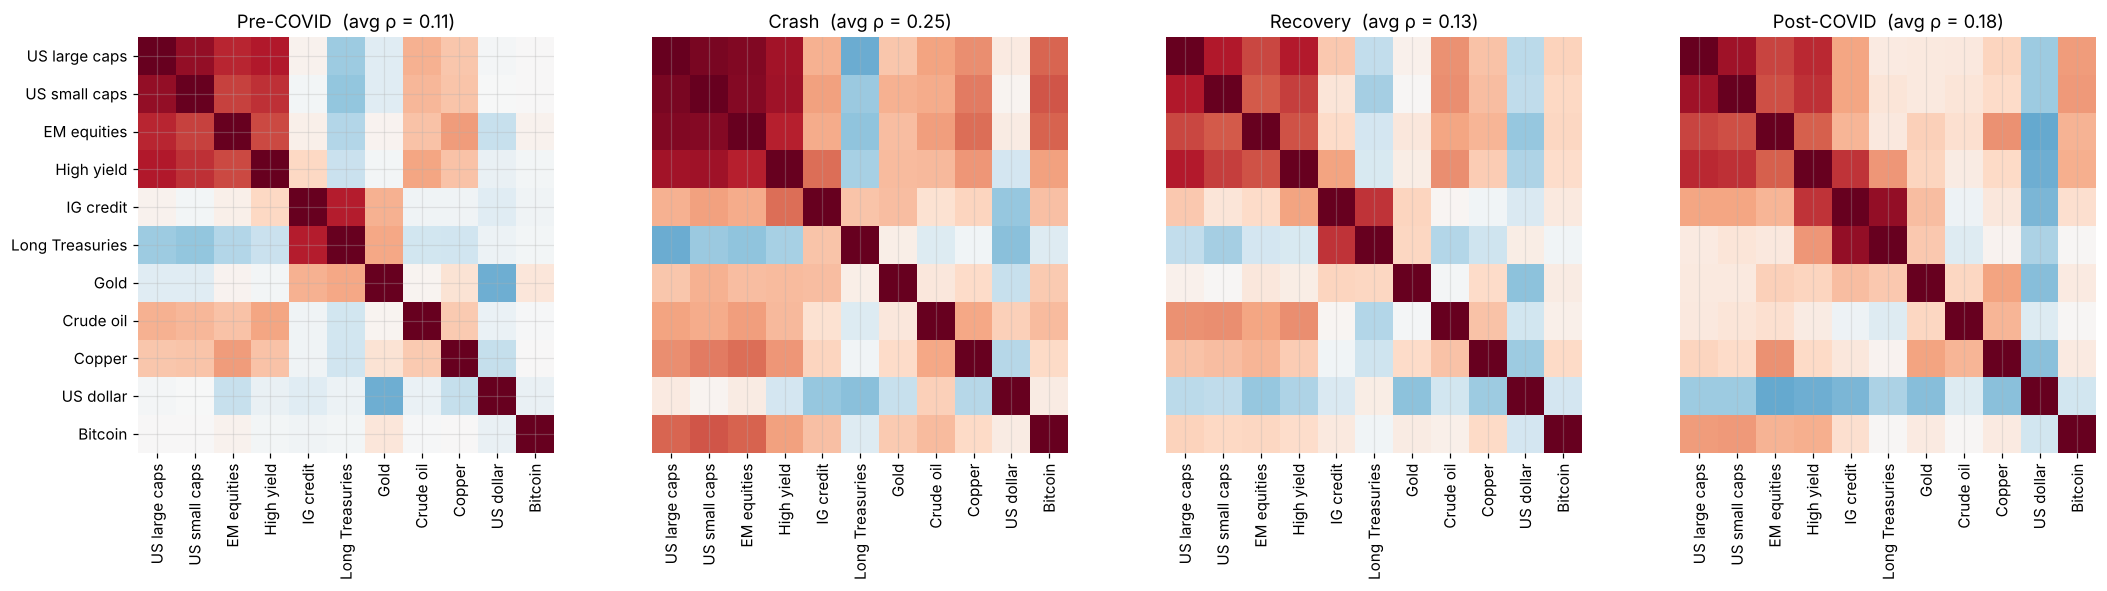

In [5]:
core = ["SPY", "IWM", "EEM", "HYG", "LQD", "TLT", "GC=F", "USO", "HG=F", "DX-Y.NYB", "BTC-USD"]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
avg = {}
for ax, p in zip(axes, D.PERIODS):
    c = D.period_slice(rets[core], p).corr(); avg[p] = correlation.average_pairwise(c)
    sns.heatmap(c, cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax, cbar=False, square=True,
                xticklabels=D.label(core), yticklabels=D.label(core) if ax is axes[0] else False)
    ax.set_title(f"{p}  (avg ρ = {avg[p]:.2f})")
fig.tight_layout(); plt.savefig(IMG / "correlation_regimes.png", bbox_inches="tight"); plt.show()

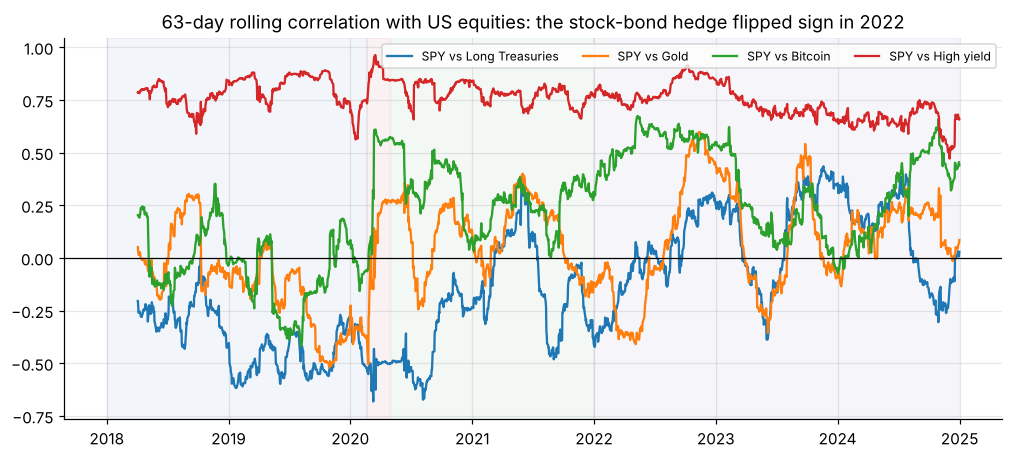

In [6]:
fig, ax = plt.subplots()
for t, lbl in [("TLT", "Long Treasuries"), ("GC=F", "Gold"), ("BTC-USD", "Bitcoin"), ("HYG", "High yield")]:
    ax.plot(correlation.rolling_corr(rets["SPY"], rets[t], 63), label=f"SPY vs {lbl}")
shade(ax); ax.axhline(0, color="k", lw=0.8)
ax.set_title("63-day rolling correlation with US equities: the stock-bond hedge flipped sign in 2022"); ax.legend(ncol=4, fontsize=8)
plt.savefig(IMG / "rolling_correlations.png", bbox_inches="tight"); plt.show()

## Was it contagion or just higher volatility?
Correlations rise mechanically when the source market becomes more volatile. The **Forbes-Rigobon** adjustment removes that effect. *Contagion* means correlation with US equities is still significantly higher in the crash **after** adjustment (one-sided Fisher z-test).

In [7]:
calm, crash = D.period_slice(rets, "Pre-COVID"), D.period_slice(rets, "Crash")
ct = correlation.contagion_table(rets, "SPY", calm, crash)
ct.index = D.label(ct.index)
ct.style.format({"calm corr": "{:.2f}", "crisis corr": "{:.2f}", "adjusted crisis corr": "{:.2f}",
                 "z (adjusted vs calm)": "{:.2f}", "p-value": "{:.3f}"})

,calm corr,crisis corr,adjusted crisis corr,z (adjusted vs calm),p-value,contagion (5%)
Bitcoin,0.00,0.58,0.16,1.01,0.157,False
US dollar,-0.02,0.09,0.02,0.25,0.401,False
EM equities,0.76,0.93,0.48,-3.14,0.999,False
Ether,0.07,0.63,0.18,0.74,0.228,False
EUR/USD,0.10,0.13,0.03,-0.49,0.688,False
Gold,-0.12,0.28,0.06,1.24,0.108,False
Copper,0.28,0.47,0.12,-1.12,0.869,False
High yield,0.80,0.84,0.33,-5.01,1.000,False
US small caps,0.88,0.95,0.55,-5.06,1.000,False
USD/JPY,0.02,-0.21,-0.05,-0.46,0.679,False


In [8]:
summary = pd.Series(avg).rename("average pairwise correlation")
print(summary.round(3).to_string())
print(f"\nAssets with statistically significant contagion from SPY after adjustment: {int(ct['contagion (5%)'].sum())} of {len(ct)}")

Pre-COVID     0.111
Crash         0.252
Recovery      0.134
Post-COVID    0.177

Assets with statistically significant contagion from SPY after adjustment: 1 of 13
